# Heart Disease Mortality Prediction Pipeline
## Jett Guitteau
### This project is a self-guided part of a learning experience at Qualees to explore machine learning methods and compare a local python machine learning pipeline with their TweenMe platform which can augment data to enhance model performance.

This project utilizes a dataset that includes medical record data of 299 heart failure patients in an attempt to predict mortality based on 11 features. The data was originally used in a research study which aimed at determining machine learning's ability to make these predictions. This project will not replicate the study, but the study contains useful information about the data, such as the origin of the data. 

The features of the dataset include demographic information age and sex; lab values includes creatinine kinase, ejection fraction, platelets, serum creatinine, and serum sodium; and comorbidities such as diabetes, high blood pressure, anemia, and whether the patient has a smoking history. The target column is "death_event" which tracks if the patient died in the time they were followed by the researchers. The original dataset contains a "time" column, which was excluded from the original study and will therefore be omitted from this project as well. 

The dataset can be found on the UC Irvine Machine Learning Repository: https://archive.ics.uci.edu/dataset/519/heart+failure+clinical+records
The original article utilizing this dataset can be found here: https://link.springer.com/article/10.1186/s12911-020-1023-5

## Imports and Basic Data Cleaning

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, cross_validate
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    RocCurveDisplay,
    get_scorer,
)
from sklearn.inspection import permutation_importance

In [2]:
heart = pd.read_csv("heart_failure_clinical_records_dataset.csv")
heart.head()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,1


In [3]:
heart.info()

<class 'pandas.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         299 non-null    int64  
 5   high_blood_pressure       299 non-null    int64  
 6   platelets                 299 non-null    float64
 7   serum_creatinine          299 non-null    float64
 8   serum_sodium              299 non-null    int64  
 9   sex                       299 non-null    int64  
 10  smoking                   299 non-null    int64  
 11  DEATH_EVENT               299 non-null    int64  
dtypes: float64(3), int64(9)
memory usage: 28.2 KB


In [4]:
heart.anaemia = heart.anaemia.astype('category')
heart.diabetes = heart.diabetes.astype('category')
heart.high_blood_pressure = heart.high_blood_pressure.astype('category')
heart.sex = heart.sex.astype('category')
heart.smoking = heart.smoking.astype('category')
heart.DEATH_EVENT = heart.DEATH_EVENT.astype('category')

In [5]:
heart.dtypes

age                          float64
anaemia                     category
creatinine_phosphokinase       int64
diabetes                    category
ejection_fraction              int64
high_blood_pressure         category
platelets                    float64
serum_creatinine             float64
serum_sodium                   int64
sex                         category
smoking                     category
DEATH_EVENT                 category
dtype: object

In [6]:
heart.describe()

,age,creatinine_phosphokinase,ejection_fraction,platelets,serum_creatinine,serum_sodium
count,299.000000,299.000000,299.000000,299.000000,299.00000,299.000000
mean,60.833893,581.839465,38.083612,263358.029264,1.39388,136.625418
std,11.894809,970.287881,11.834841,97804.236869,1.03451,4.412477
min,40.000000,23.000000,14.000000,25100.000000,0.50000,113.000000
25%,51.000000,116.500000,30.000000,212500.000000,0.90000,134.000000
50%,60.000000,250.000000,38.000000,262000.000000,1.10000,137.000000
75%,70.000000,582.000000,45.000000,303500.000000,1.40000,140.000000
max,95.000000,7861.000000,80.000000,850000.000000,9.40000,148.000000


In [7]:
heart[heart["serum_sodium"] == 113] # Investigating suspicious value in serum_sodium column

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,DEATH_EVENT
199,60.0,0,1211,1,35,0,263358.03,1.8,113,1,1,0


In [8]:
heart.serum_sodium.value_counts(sort=False).sort_index().head(10) # Investigating suspicious values in serum_sodium column

serum_sodium
113    1
116    1
121    1
124    1
125    1
126    1
127    3
128    2
129    2
130    9
Name: count, dtype: int64

In [9]:
heart.creatinine_phosphokinase.value_counts(sort=False).sort_index(ascending=False).head(10)

creatinine_phosphokinase
7861    1
7702    1
5882    1
5209    1
4540    1
3966    1
3964    1
2794    1
2695    1
2656    1
Name: count, dtype: int64

In [10]:
heart.nlargest(2, 'creatinine_phosphokinase') # Investigating the rows with the highest values of creatinine_phosphokinase. 

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,DEATH_EVENT
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,1
60,45.0,0,7702,1,25,1,390000.00,1.0,139,1,0,1


In [11]:
heart[heart["serum_creatinine"] == 9.4] # Investigating suspicious value in serum_creatinine column

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,DEATH_EVENT
9,80.0,1,123,0,35,1,388000.0,9.4,133,1,1,1


In [12]:
heart.serum_creatinine.value_counts(sort=False).sort_index(ascending=False).head(10)

serum_creatinine
9.4    1
9.0    1
6.8    1
6.1    1
5.8    1
5.0    1
4.4    1
4.0    1
3.8    1
3.7    1
Name: count, dtype: int64

The three investigated lab values here were ones that showed notable extreme values in `heart.describe()`, but as we see they are not the same patient. Investigating the 10 most extreme values in their respective directions we can see many abnormal values, which are all possible and indicate comorbidities (such as kidney failure in the cases of high serum creatinine) or acute events (such as a potential myocardial infarction for the elevated creatinine phosphokinase), which are expected in a patient population such as this one. As these are possible values, and as it's a well known dataset from a peer reviewed study, they are likely true values. Additionally, they are likely influential on the target and will be useful for the models. Both records with the highest creatinine phosphokinase values have DEATH_EVENT = 1. This is a descriptive observation only and the values were retained based on data validity and clinical plausibility, not their outcomes. 

In [13]:
heart.isna().sum() # No missing values in the dataset

age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
DEATH_EVENT                 0
dtype: int64

In [14]:
# Investigating the values of the platelets since it is dtype float.
heart.platelets.value_counts()

platelets
263358.03    25
237000.00     4
228000.00     4
226000.00     4
305000.00     4
             ..
543000.00     1
382000.00     1
179000.00     1
155000.00     1
742000.00     1
Name: count, Length: 176, dtype: int64

In [15]:
round(heart.platelets.mean(), 2) # Verifying if the 25 values match the mean to see if suspicion that they are imputed is probably correct.

np.float64(263358.03)

**Data quality note:** The dataset is presented as having no missing values, but `platelets` and `age` are stored as floats even though most of their values are whole numbers. Investigating this showed that 25 `platelets` rows equal the column mean (263358.03), consistent with mean imputation of originally missing values. The non-whole `age` values (60.667) do not equal the column mean, so `age` was either imputed by a different method or altered in some other way. Because the method is unknown, some whole-number ages may also have been imputed and would not be detectable by a mean check. Other columns may contain undetected imputed values as well. Distributions and relationships involving affected columns may therefore not reflect the true underlying values, since imputed values add no real variation.

In [16]:
heart.duplicated().sum() # Check for duplicate rows in the dataset.

np.int64(0)

## EDA

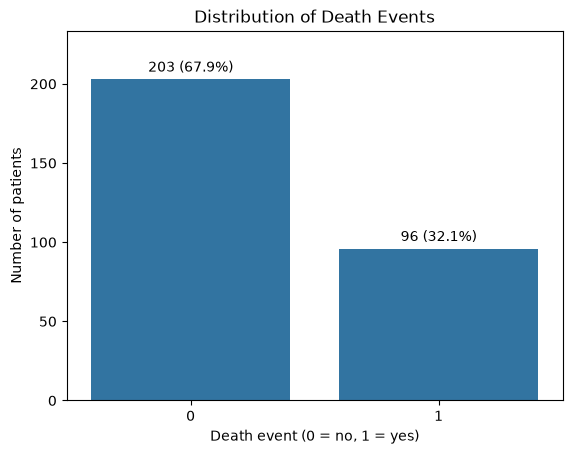

<Figure size 640x480 with 0 Axes>

In [17]:
# Creating a count plot for the distribution of death events
ax = sns.countplot(data=heart, x="DEATH_EVENT", order=[0, 1])
target_counts = heart["DEATH_EVENT"].value_counts().reindex([0, 1])
ax.bar_label(
    ax.containers[0],
    labels=[f"{count} ({count / len(heart):.1%})" for count in target_counts],
    padding=3
)
ax.margins(y=0.15)
plt.title("Distribution of Death Events")
plt.xlabel("Death event (0 = no, 1 = yes)")
plt.ylabel("Number of patients")
plt.show()
plt.clf()

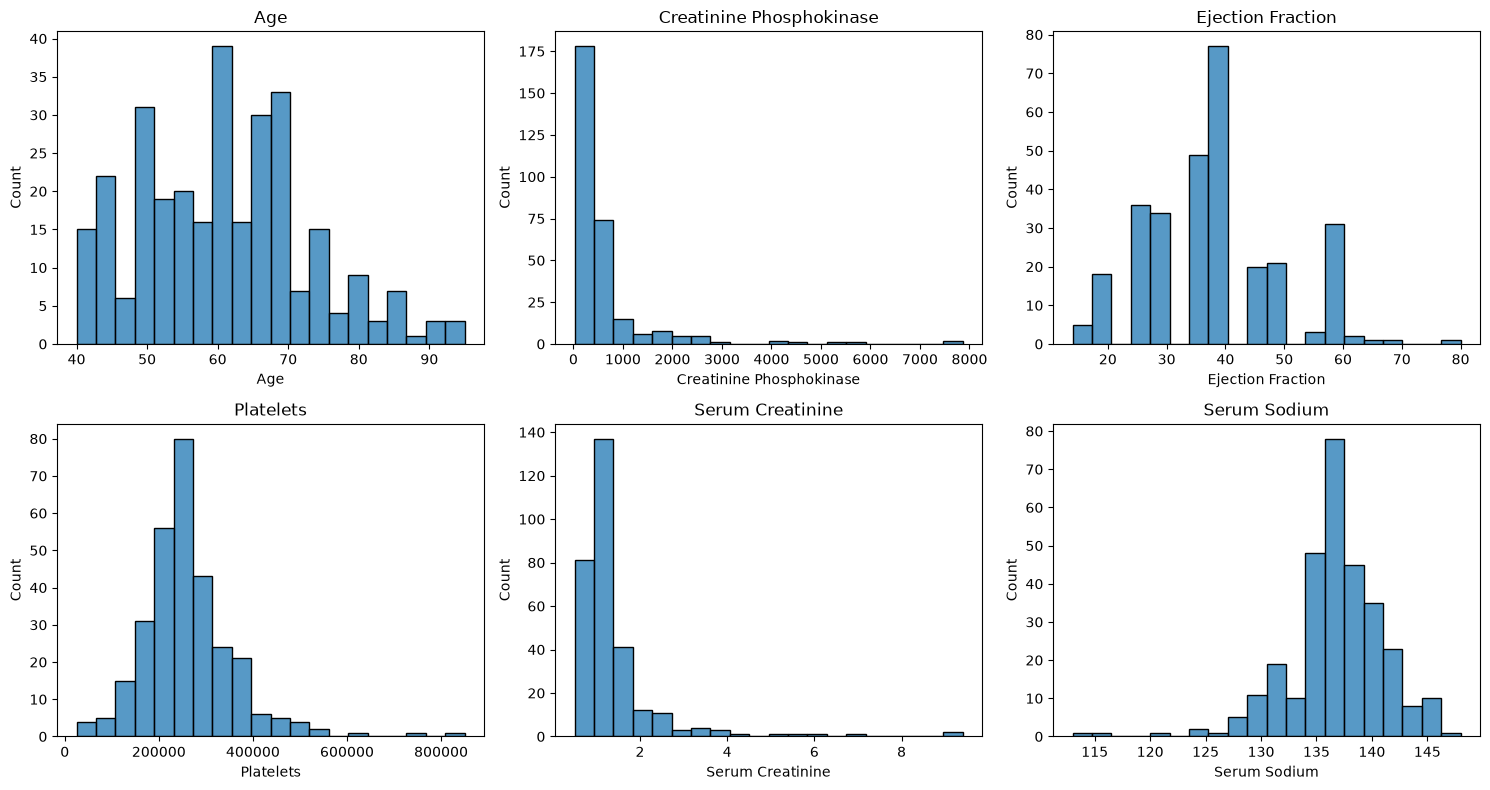

<Figure size 640x480 with 0 Axes>

In [18]:
# Visualizing the distribution of numeric columns
numeric_cols = [
    "age",
    "creatinine_phosphokinase",
    "ejection_fraction",
    "platelets",
    "serum_creatinine",
    "serum_sodium"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for column, ax in zip(numeric_cols, axes.flat):
    sns.histplot(data=heart, x=column, bins=20, ax=ax)
    ax.set_title(column.replace("_", " ").title())
    ax.set_xlabel(column.replace("_", " ").title())
    ax.set_ylabel("Count")

plt.tight_layout()
plt.show()
plt.clf()

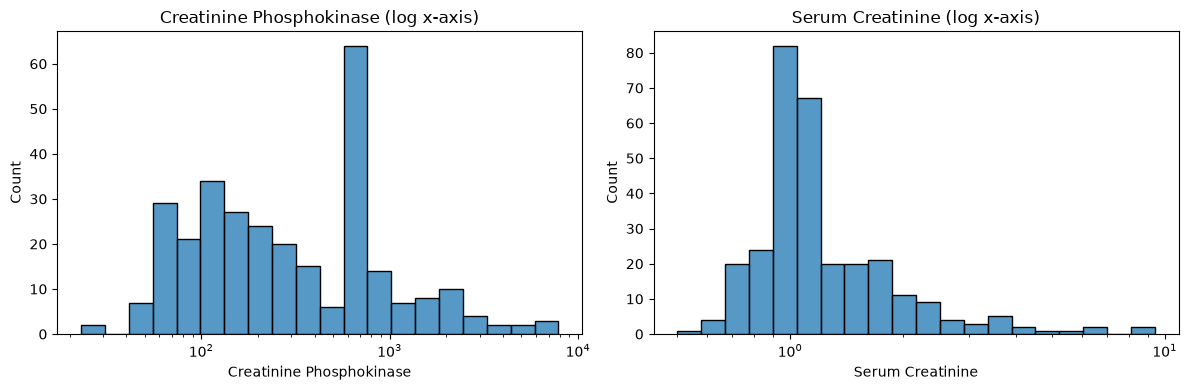

<Figure size 640x480 with 0 Axes>

In [19]:
log_cols = ["creatinine_phosphokinase", "serum_creatinine"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for column, ax in zip(log_cols, axes):
    sns.histplot(data=heart, x=column, bins=20, log_scale=True, ax=ax)
    ax.set_title(column.replace("_", " ").title() + " (log x-axis)")
    ax.set_xlabel(column.replace("_", " ").title())
    ax.set_ylabel("Count")

plt.tight_layout()
plt.show()
plt.clf()

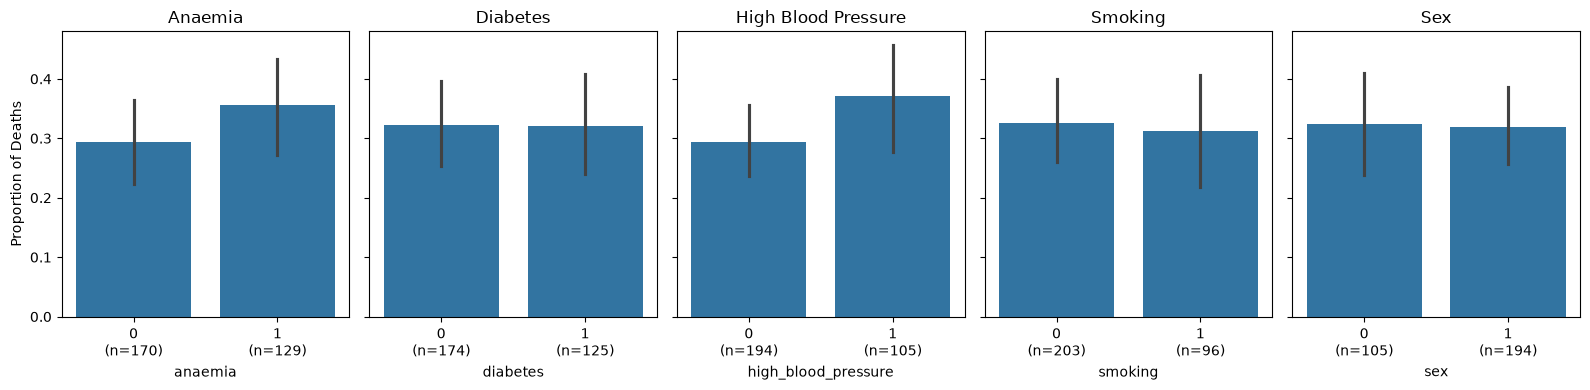

<Figure size 640x480 with 0 Axes>

In [20]:
binary_cols = ["anaemia", "diabetes", "high_blood_pressure", "smoking", "sex"]
plot_data = heart.assign(DEATH_EVENT=heart["DEATH_EVENT"].astype(int))

fig, axes = plt.subplots(1, len(binary_cols), figsize=(16, 4), sharey=True)

for ax, col in zip(axes, binary_cols):
    sns.barplot(x=col, y="DEATH_EVENT", data=plot_data, order=[0, 1], ax=ax)
    group_counts = plot_data[col].value_counts().reindex([0, 1], fill_value=0)
    ax.set_xticks([0, 1], labels=[f"{group}\n(n={count})" for group, count in group_counts.items()])
    ax.set_title(col.replace("_", " ").title())
    ax.set_xlabel(col)
    ax.set_ylabel("Proportion of Deaths")

plt.tight_layout()
plt.show()
plt.clf()

Observed differences in death proportions between groups are small relative to their uncertainty. The error bars show bootstrap 95% confidence intervals for each group's estimated death proportion, not measurement error. Overlap between these intervals does not establish that there is no association; these plots alone do not establish whether an association exists.

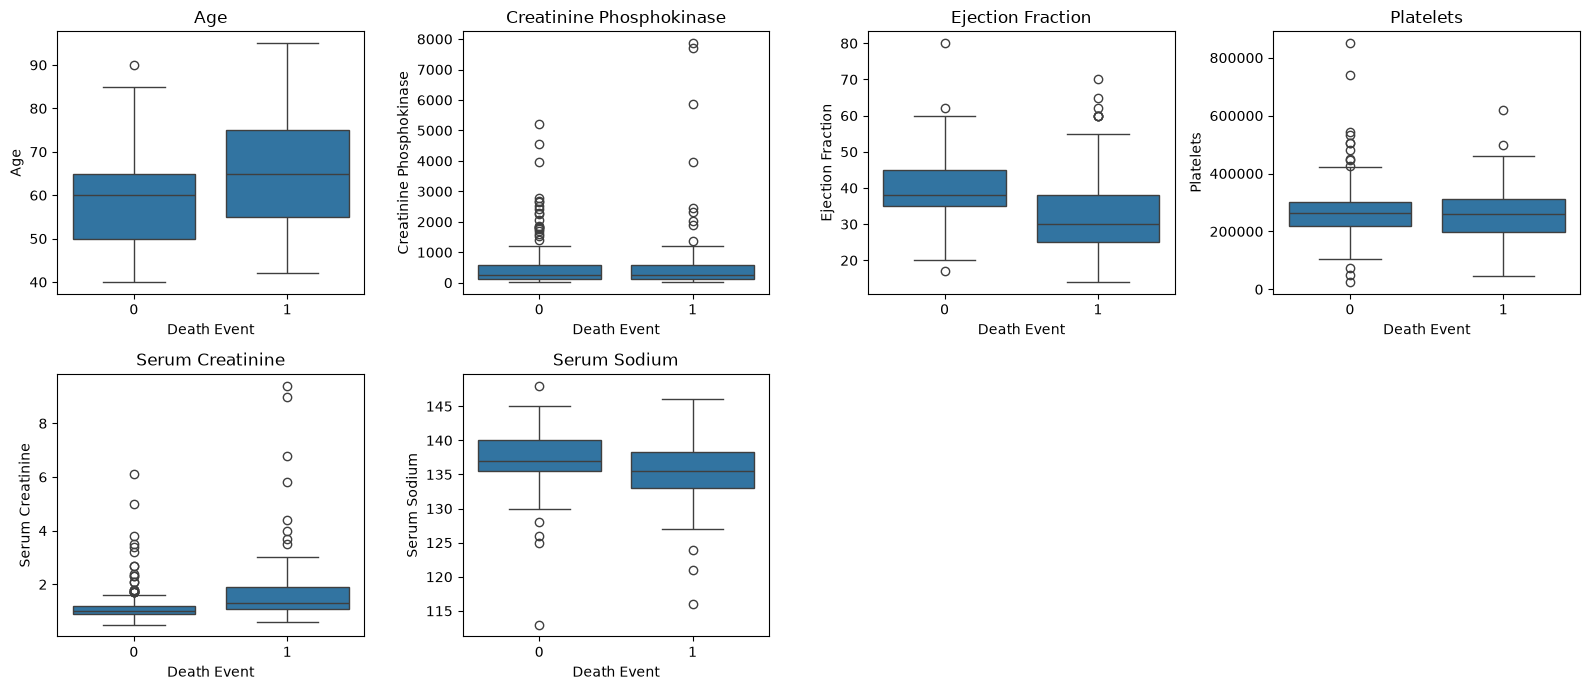

<Figure size 640x480 with 0 Axes>

In [21]:
num_cols = ["age", "creatinine_phosphokinase", "ejection_fraction",
            "platelets", "serum_creatinine", "serum_sodium"]

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.flatten()

for ax, col in zip(axes, num_cols):
    sns.boxplot(x="DEATH_EVENT", y=col, data=heart, ax=ax)
    ax.set_title(col.replace("_", " ").title())
    ax.set_xlabel("Death Event")
    ax.set_ylabel(col.replace("_", " ").title())

# hide the unused 8th panel
for ax in axes[len(num_cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()
plt.clf()

The graphs show us that there are more potential relationships between the values of the numeric columns and which are more associated with deaths. Notably, older age, lower ejection fraction, and higher serum creatinine seem suspicious.

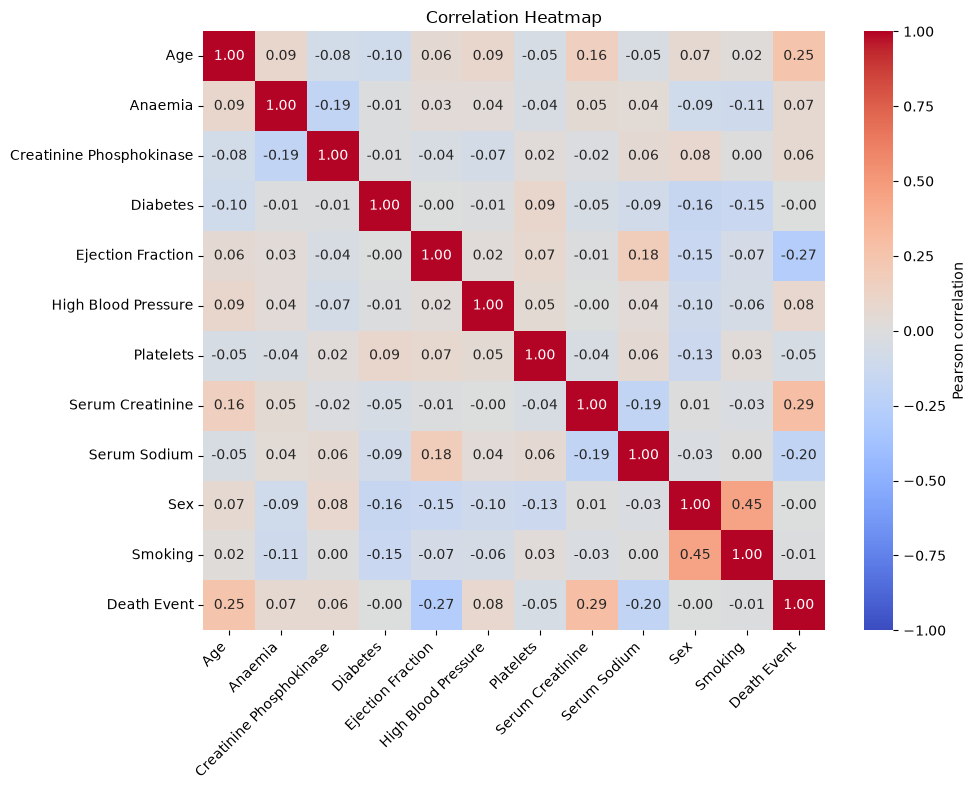

<Figure size 640x480 with 0 Axes>

In [22]:
corr = heart.corr(numeric_only=False)

pretty = lambda s: s.replace("_", " ").title()
corr = corr.rename(index=pretty, columns=pretty)

plt.figure(figsize=(10, 8))
ax = sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1, vmax=1,
    cbar_kws={"label": "Pearson correlation"},
)
ax.set_title("Correlation Heatmap")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()
plt.clf()

The largest absolute pairwise Pearson correlation among the predictors is approximately 0.45, between sex and smoking. No strong pairwise linear correlations are apparent, but this alone does not rule out multicollinearity involving several predictors or nonlinear relationships. Correlations with DEATH_EVENT describe associations with the target, not collinearity among predictors.

## Modeling

In [23]:
X = heart.drop(columns="DEATH_EVENT")
y = heart["DEATH_EVENT"]
print(X.columns.tolist())

['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes', 'ejection_fraction', 'high_blood_pressure', 'platelets', 'serum_creatinine', 'serum_sodium', 'sex', 'smoking']


In [24]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)
print(y_train.shape, y_test.shape)

(239, 11) (60, 11)
(239,) (60,)


In [25]:
# Creation of a function to write a report for model evaluation. 

def report(name, model):
    for label, Xs, ys in [("train", X_train, y_train), ("test", X_test, y_test)]:
        p = model.predict(Xs)
        print(f"{name:6} {label:5} Accuracy={accuracy_score(ys, p):.3f}  "
              f"Precision={precision_score(ys, p):.3f}  "
              f"Recall={recall_score(ys, p):.3f}  "
              f"F1={f1_score(ys, p):.3f}  "
              f"AUC={get_scorer('roc_auc')(model, Xs, ys):.3f}"
              )

In [26]:
cat_cols = X.select_dtypes(include=['object', 'category']).columns
cat_cols

X[cat_cols] = X[cat_cols].astype(int)
y = y.astype(int)

### Random Forest

In [27]:
rfpipe = Pipeline([
    ('classifier', RandomForestClassifier(random_state=42))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(rfpipe, X_train, y_train, cv=cv, scoring="f1")
print(f"Scores for each fold: {scores}")
print(f"Mean F1 score across folds: {scores.mean()}")

Scores for each fold: [0.54545455 0.54545455 0.53333333 0.4        0.46153846]
Mean F1 score across folds: 0.4971561771561771


In [28]:
param_grid = {
    "classifier__max_depth": [3, 5, 8, None],
    "classifier__min_samples_leaf": [3, 5, 7],
    "classifier__n_estimators": [100, 300],
    "classifier__class_weight": [None, "balanced"]
}

rfgrid = GridSearchCV(rfpipe, param_grid, cv=StratifiedKFold(5, shuffle=True, random_state=42), scoring="f1")

rfgrid.fit(X_train, y_train)
print(rfgrid.best_params_)
print(rfgrid.best_score_)
report("RF", rfgrid)

{'classifier__class_weight': 'balanced', 'classifier__max_depth': 5, 'classifier__min_samples_leaf': 5, 'classifier__n_estimators': 100}
0.6414321815183884
RF     train Accuracy=0.837  Precision=0.716  Recall=0.818  F1=0.764  AUC=0.937
RF     test  Accuracy=0.700  Precision=0.520  Recall=0.684  F1=0.591  AUC=0.792


The mean f1 score across the default random forest classifier was 0.49, while tuning was able to improve that to 0.59. 

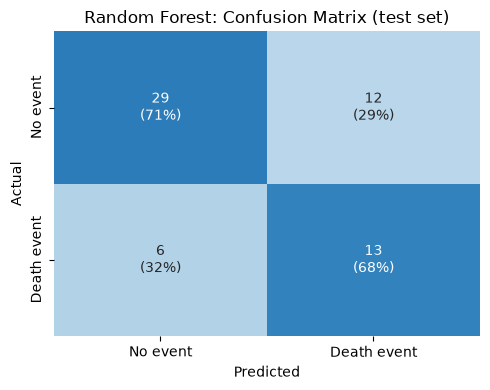

In [59]:
# Confusion matrix for Random Forest with percentages for the test set

pred = rfgrid.predict(X_test)
cm = confusion_matrix(y_test, pred)
cm_pct = cm / cm.sum(axis=1, keepdims=True)   # each row sums to 1

labels = np.array([[f"{n}\n({p:.0%})" for n, p in zip(row_n, row_p)]
                   for row_n, row_p in zip(cm, cm_pct)])

plt.figure(figsize=(5, 4))
sns.heatmap(cm_pct, annot=labels, fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False,
            xticklabels=["No event", "Death event"],
            yticklabels=["No event", "Death event"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest: Confusion Matrix (test set)")
plt.tight_layout()
plt.show()

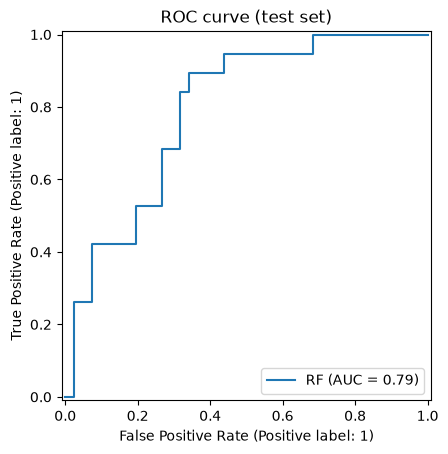

In [30]:
RocCurveDisplay.from_estimator(rfgrid, X_test, y_test, name="RF")
plt.title("ROC curve (test set)")
plt.show()

### Ridge Classifier

In [31]:
ridgepipe = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', RidgeClassifier(random_state=42))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(ridgepipe, X_train, y_train, cv=cv, scoring="f1")
print(f"Scores for each fold: {scores}")
print(f"Mean F1 score across folds: {scores.mean()}")

Scores for each fold: [0.55172414 0.58333333 0.48       0.41666667 0.4       ]
Mean F1 score across folds: 0.48634482758620684


In [32]:
param_grid = {
    "classifier__alpha": [0.1, 1, 5, 10, 15, 20],
    "classifier__class_weight": [None, "balanced"],
}

ridgegrid = GridSearchCV(ridgepipe, param_grid, cv=StratifiedKFold(5, shuffle=True, random_state=42), scoring="f1")

ridgegrid.fit(X_train, y_train)
print(ridgegrid.best_params_)
print(ridgegrid.best_score_)
report("Ridge", ridgegrid)

{'classifier__alpha': 0.1, 'classifier__class_weight': 'balanced'}
0.659210057228633
Ridge  train Accuracy=0.753  Precision=0.587  Recall=0.792  F1=0.674  AUC=0.817
Ridge  test  Accuracy=0.700  Precision=0.526  Recall=0.526  F1=0.526  AUC=0.757


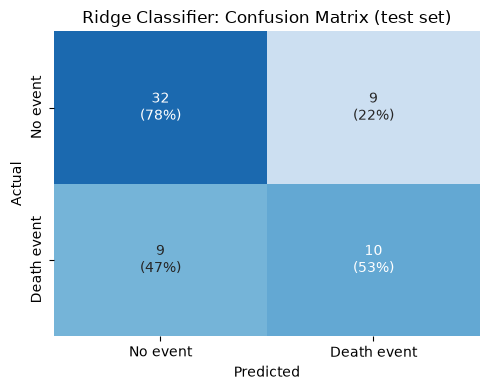

In [56]:
# Confusion matrix for Ridge Classifier with percentages for the test set

pred = ridgegrid.predict(X_test)
cm = confusion_matrix(y_test, pred)
cm_pct = cm / cm.sum(axis=1, keepdims=True)   # each row sums to 1

labels = np.array([[f"{n}\n({p:.0%})" for n, p in zip(row_n, row_p)]
                   for row_n, row_p in zip(cm, cm_pct)])

plt.figure(figsize=(5, 4))
sns.heatmap(cm_pct, annot=labels, fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False,
            xticklabels=["No event", "Death event"],
            yticklabels=["No event", "Death event"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Ridge Classifier: Confusion Matrix (test set)")
plt.tight_layout()
plt.show()

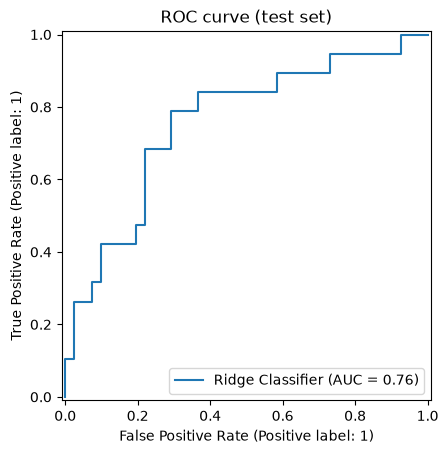

In [34]:
RocCurveDisplay.from_estimator(ridgegrid, X_test, y_test, name="Ridge Classifier")
plt.title("ROC curve (test set)")
plt.show()

### Support Vector Classification

In [35]:
svcpipe = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', SVC(random_state=42))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(svcpipe, X_train, y_train, cv=cv, scoring="f1")
print(f"Scores for each fold: {scores}")
print(f"Mean F1 score across folds: {scores.mean()}")

Scores for each fold: [0.58064516 0.47619048 0.4        0.48       0.52173913]
Mean F1 score across folds: 0.4917149535831163


In [36]:
param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10, 100],
    'classifier__gamma': [1, 0.1, 0.01],
    'classifier__kernel': ['rbf', 'linear'],
    'classifier__class_weight': [None, 'balanced'],
}

svcgrid = GridSearchCV(svcpipe, param_grid, cv=StratifiedKFold(5, shuffle=True, random_state=42), scoring="f1")

svcgrid.fit(X_train, y_train)
print(svcgrid.best_params_)
print(svcgrid.best_score_)
report("SVC", svcgrid)

{'classifier__C': 100, 'classifier__class_weight': 'balanced', 'classifier__gamma': 1, 'classifier__kernel': 'linear'}
0.6841938178780284
SVC    train Accuracy=0.782  Precision=0.626  Recall=0.805  F1=0.705  AUC=0.834
SVC    test  Accuracy=0.667  Precision=0.476  Recall=0.526  F1=0.500  AUC=0.693


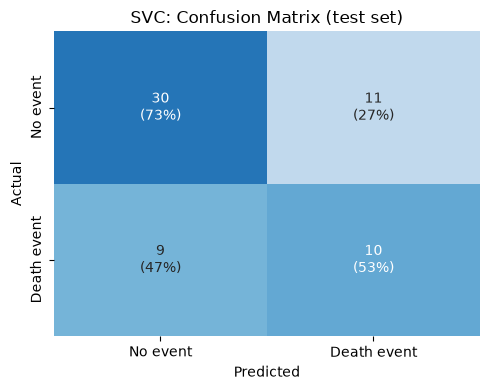

In [54]:
# Confusion matrix for SVC with percentages for the test set

pred = svcgrid.predict(X_test)
cm = confusion_matrix(y_test, pred)
cm_pct = cm / cm.sum(axis=1, keepdims=True)   # each row sums to 1

labels = np.array([[f"{n}\n({p:.0%})" for n, p in zip(row_n, row_p)]
                   for row_n, row_p in zip(cm, cm_pct)])

plt.figure(figsize=(5, 4))
sns.heatmap(cm_pct, annot=labels, fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False,
            xticklabels=["No event", "Death event"],
            yticklabels=["No event", "Death event"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("SVC: Confusion Matrix (test set)")
plt.tight_layout()
plt.show()

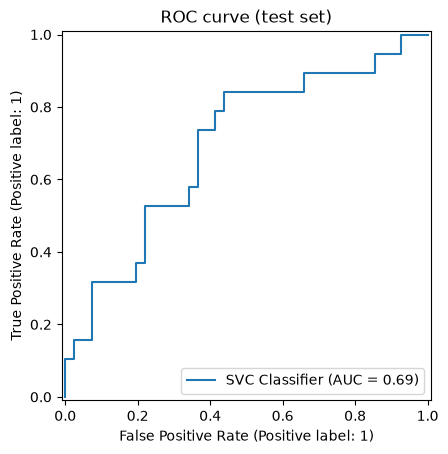

In [38]:
RocCurveDisplay.from_estimator(svcgrid, X_test, y_test, name="SVC Classifier")
plt.title("ROC curve (test set)")
plt.show()

### XGBoost

In [39]:
xgbpipe = Pipeline([
    ('classifier', XGBClassifier(random_state=42))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(xgbpipe, X_train, y_train, cv=cv, scoring="f1")
print(f"Scores for each fold: {scores}")
print(f"Mean F1 score across folds: {scores.mean()}")

Scores for each fold: [0.55555556 0.52173913 0.51612903 0.59259259 0.57142857]
Mean F1 score across folds: 0.5514889764539133


In [40]:
ratio = (y_train == 0).sum() / (y_train == 1).sum()

param_grid = {
    'classifier__n_estimators': [50, 75, 100],
    'classifier__max_depth': [2, 3, 5],
    'classifier__learning_rate': [0.01, 0.03, 0.05],
    "classifier__min_child_weight": [1, 3, 5], 
    "classifier__scale_pos_weight": [1, ratio],
}

xgbgrid = GridSearchCV(xgbpipe, param_grid, cv=StratifiedKFold(5, shuffle=True, random_state=42), scoring="f1")

xgbgrid.fit(X_train, y_train)
print(xgbgrid.best_params_)
print(xgbgrid.best_score_)
report("XGB", xgbgrid)

{'classifier__learning_rate': 0.05, 'classifier__max_depth': 3, 'classifier__min_child_weight': 3, 'classifier__n_estimators': 50, 'classifier__scale_pos_weight': np.float64(2.103896103896104)}
0.6371473750790638
XGB    train Accuracy=0.845  Precision=0.733  Recall=0.818  F1=0.773  AUC=0.931
XGB    test  Accuracy=0.733  Precision=0.565  Recall=0.684  F1=0.619  AUC=0.793


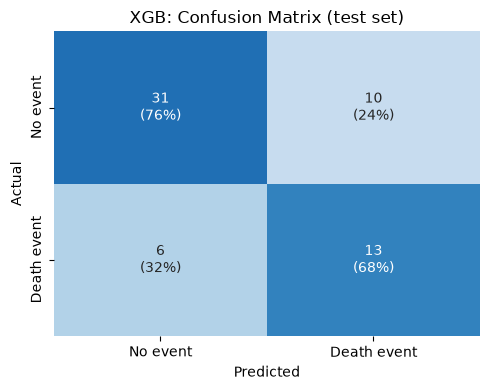

In [55]:
# Confusion matrix for SVC with percentages for the test set

pred = xgbgrid.predict(X_test)
cm = confusion_matrix(y_test, pred)
cm_pct = cm / cm.sum(axis=1, keepdims=True)   # each row sums to 1

labels = np.array([[f"{n}\n({p:.0%})" for n, p in zip(row_n, row_p)]
                   for row_n, row_p in zip(cm, cm_pct)])

plt.figure(figsize=(5, 4))
sns.heatmap(cm_pct, annot=labels, fmt="", vmin=0, vmax=1, cmap="Blues", cbar=False,
            xticklabels=["No event", "Death event"],
            yticklabels=["No event", "Death event"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("XGB: Confusion Matrix (test set)")
plt.tight_layout()
plt.show()

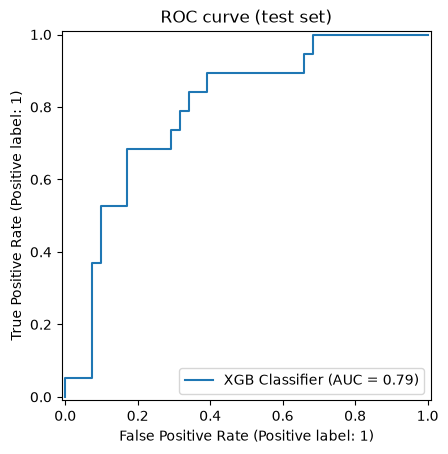

In [42]:
RocCurveDisplay.from_estimator(xgbgrid, X_test, y_test, name="XGB Classifier")
plt.title("ROC curve (test set)")
plt.show()

### Comparing Models

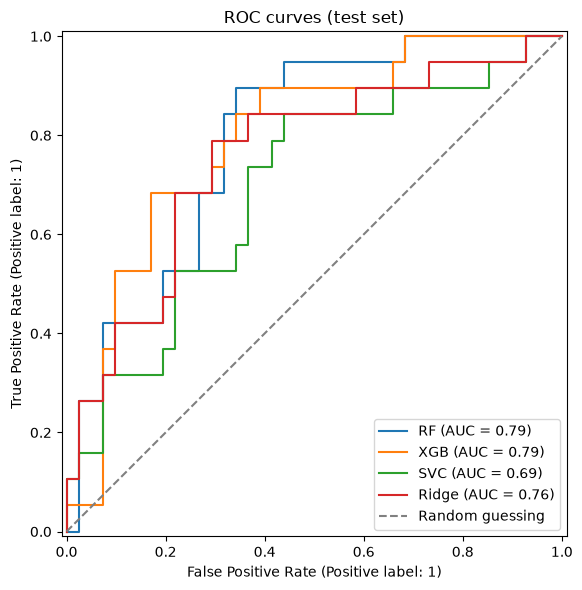

In [43]:
fig, ax = plt.subplots(figsize=(6, 6))

RocCurveDisplay.from_estimator(rfgrid, X_test, y_test, name="RF", ax=ax)
RocCurveDisplay.from_estimator(xgbgrid, X_test, y_test, name="XGB", ax=ax)
RocCurveDisplay.from_estimator(svcgrid, X_test, y_test, name="SVC", ax=ax)
RocCurveDisplay.from_estimator(ridgegrid, X_test, y_test, name="Ridge", ax=ax)

ax.plot([0, 1], [0, 1], "--", color="gray", label="Random guessing")
ax.set_title("ROC curves (test set)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

The ROC curves for all four models overlap closely, so none stands out clearly. With only ~60 test rows, the curves are jagged and small differences are not reliable. To compare the models more robustly, I re-score each tuned model with 5-fold cross-validation on the training data, reporting the mean and standard deviation of several metrics. The test set is not used in this step.

In [44]:
cv = StratifiedKFold(5, shuffle=True, random_state=42)
grids = {"RF": rfgrid, "XGB": xgbgrid, "SVC": svcgrid, "Ridge": ridgegrid}
metrics = ["accuracy", "precision", "recall", "f1", "roc_auc"]

rows = []
for name, g in grids.items():
    res = cross_validate(g.best_estimator_, X_train, y_train, cv=cv, scoring=metrics)
    row = {"Model": name}
    for m in metrics:
        row[f"{m}_mean"] = res[f"test_{m}"].mean()
        row[f"{m}_std"] = res[f"test_{m}"].std()
    rows.append(row)

cv_table = pd.DataFrame(rows).set_index("Model")
cv_table.round(3)

,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std
Model,,,,,,,,,,
RF,0.765,0.068,0.651,0.130,0.648,0.104,0.641,0.094,0.791,0.051
XGB,0.749,0.049,0.610,0.093,0.688,0.116,0.637,0.064,0.753,0.041
SVC,0.778,0.025,0.634,0.035,0.753,0.105,0.684,0.040,0.819,0.050
Ridge,0.753,0.051,0.600,0.070,0.742,0.106,0.659,0.063,0.791,0.062


All four models perform similarly in cross-validation (ROC-AUC ≈ 0.79). XGBoost has the highest F1 (0.71) and recall (0.80), but its advantage is within fold-to-fold variability. With a small dataset and weak features, model choice matters less than the information in the features, so the comparison is inconclusive.

## Investigating Feature Importance
To get a general idea of which features matter most, I use permutation importance on the tuned random forest only. Since the four models performed similarly in cross-validation, one model gives a reasonable overview. The results describe what this model relies on, so they may differ for the other models.

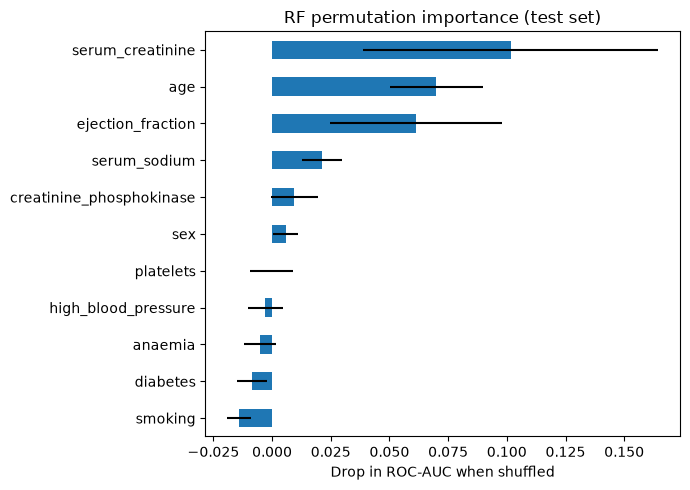

In [45]:
r = permutation_importance(
    rfgrid.best_estimator_, X_test, y_test,
    scoring="roc_auc", n_repeats=30, random_state=42,
)

imp = pd.DataFrame({"mean": r.importances_mean, "std": r.importances_std},
                   index=X_test.columns).sort_values("mean")

imp["mean"].plot(kind="barh", xerr=imp["std"], figsize=(7, 5))
plt.xlabel("Drop in ROC-AUC when shuffled")
plt.title("RF permutation importance (test set)")
plt.tight_layout()
plt.show()

Permutation importance on the tuned random forest points to a small group of numeric features carrying most of the signal: serum creatinine, age, ejection fraction, and (more weakly) serum sodium. Serum creatinine ranked highest, but the error bars of the top three overlap, so their order should not be over-interpreted. Between two different train/test splits, ejection fraction moved from first to third place and age rose, which shows how sensitive the ranking is with only ~60 test rows. The binary features (anaemia, diabetes, high blood pressure, smoking, sex) had importance near zero. The prominence of serum creatinine and ejection fraction is consistent with the original study of this dataset. Overall, none of the models predicted death events reliably. In 5-fold cross-validation, ROC-AUC ranged from 0.75 to 0.82, F1 from 0.64 to 0.68, and precision only from 0.60 to 0.65, even after class weighting raised recall to roughly 0.65-0.75. SVC scored nominally highest on most metrics, but its margins over the other models were within one standard deviation (fold-to-fold std of 0.04-0.13), so the models are effectively tied. The ranking also changed after the train/test split was stratified (XGBoost was nominally best before), which shows how sensitive these comparisons are. Because four very different algorithms land in the same range, the limit appears to lie in the data rather than the algorithm: the dataset is small (~300 rows), most features carry little signal (see the importance results), and the strongest predictor, follow-up time, was excluded. A more reliable model would likely need more records and more informative features, and it would need to be validated on independent data before any practical use.

Next steps could include testing other models or trying to find tune models further; however, given the data limitations further tuning is unlikely to provide significantly better results. Therefore, the next step will be to utilize TweenMe by Qualees to augment the data and evaluate model performance once there is more data available, albeit synthetic data.